# What is a put option? — a visual explanation

A **put option** gives the holder the **right, but not the obligation**, to **sell** one share at a fixed **strike price K** on the **expiry date T**.

- If NWR ends **below K** at expiry, the put pays **K − S(T)**.
- If NWR ends **above K**, the put expires worthless (payoff 0).

All numbers here are made up for illustration. Option values use the Black–Scholes formula (constant volatility) to keep the picture simple; the Heston model on the next slide makes volatility random.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---- Edit these to change the story ----------------------------------
COMPANY = "Company (CMPY)"
S0    = 100.0   # stock price today ($)
K     = 100.0   # strike price ($)
T     = 1.0     # time to expiry (years)
r     = 0.04    # risk-free rate
sigma = 0.30    # volatility
N     = 252     # trading days until expiry
SEED  = 38      # change for a different random walk
# ----------------------------------------------------------------------

# Minimal, white, presentation-friendly style
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "font.size": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.labelcolor": "#222",
    "xtick.color": "#444", "ytick.color": "#444",
})
STOCK, STRIKE, PUT, GREY = "#1f3b73", "#c0392b", "#2e8b57", "#9a9a9a"
SAVE = True   # also write PNGs for the slides

## 1. Simulate a random walk for CMPY

In [2]:
rng = np.random.default_rng(SEED)
dt = T / N
t = np.linspace(0, T, N + 1)
z = rng.standard_normal(N)
log_steps = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
S = S0 * np.exp(np.concatenate([[0], np.cumsum(log_steps)]))

print(f"Start: ${S[0]:.2f}   End at T: ${S[-1]:.2f}   Payoff: ${max(K - S[-1], 0):.2f}")

Start: $100.00   End at T: $85.59   Payoff: $14.41


## 2. The stock path, the strike K, and the expiry T

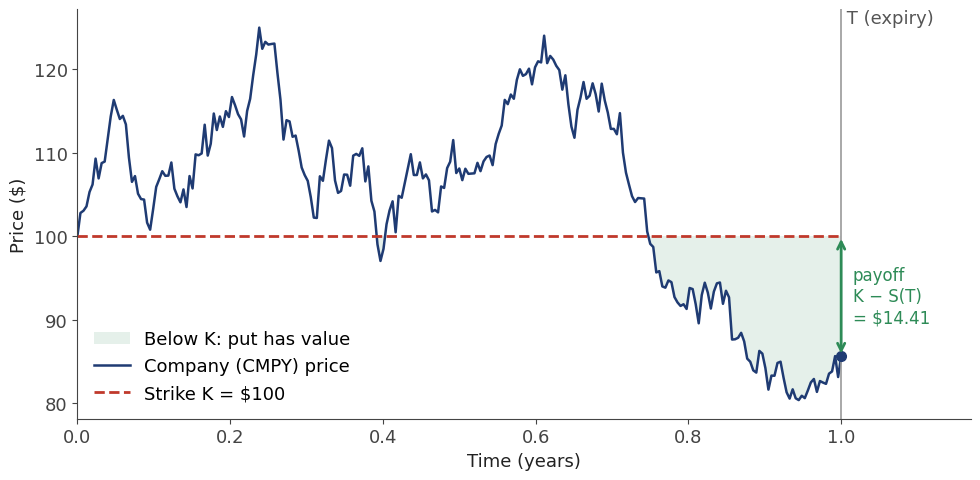

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(t, S, K, where=S < K, color=PUT, alpha=0.12, lw=0,
                label="Below K: put has value")
ax.plot(t, S, color=STOCK, lw=1.8, label=f"{COMPANY} price")
ax.hlines(K, 0, T, color=STRIKE, lw=2, ls="--", label=f"Strike K = ${K:.0f}")
ax.axvline(T, color=GREY, lw=1.2)
ax.text(T, ax.get_ylim()[1], " T (expiry)", color="#555", va="top", ha="left")

# Payoff at expiry
payoff = max(K - S[-1], 0)
ax.plot(T, S[-1], "o", color=STOCK, ms=7)
if payoff > 0:
    ax.annotate("", xy=(T, S[-1]), xytext=(T, K),
                arrowprops=dict(arrowstyle="<->", color=PUT, lw=2))
    ax.text(T * 1.015, (K + S[-1]) / 2, f"payoff\nK − S(T)\n= ${payoff:.2f}",
            color=PUT, ha="left", va="center", fontsize=12)

ax.set_xlim(0, T * 1.17)
ax.set_xlabel("Time (years)")
ax.set_ylabel("Price ($)")
# ax.set_title("A put option on a random stock path", loc="left", fontsize=15)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
if SAVE: plt.savefig("fig1_path_and_strike.png", dpi=200)
plt.show()

## 3. How the put's value changes over time

Black–Scholes put value at each day, using that day's price and the time left until T.
The dashed line is the **intrinsic value** max(K − S, 0), what it would pay if it expired right now. The gap between the two is **time value**, which shrinks to zero at expiry.

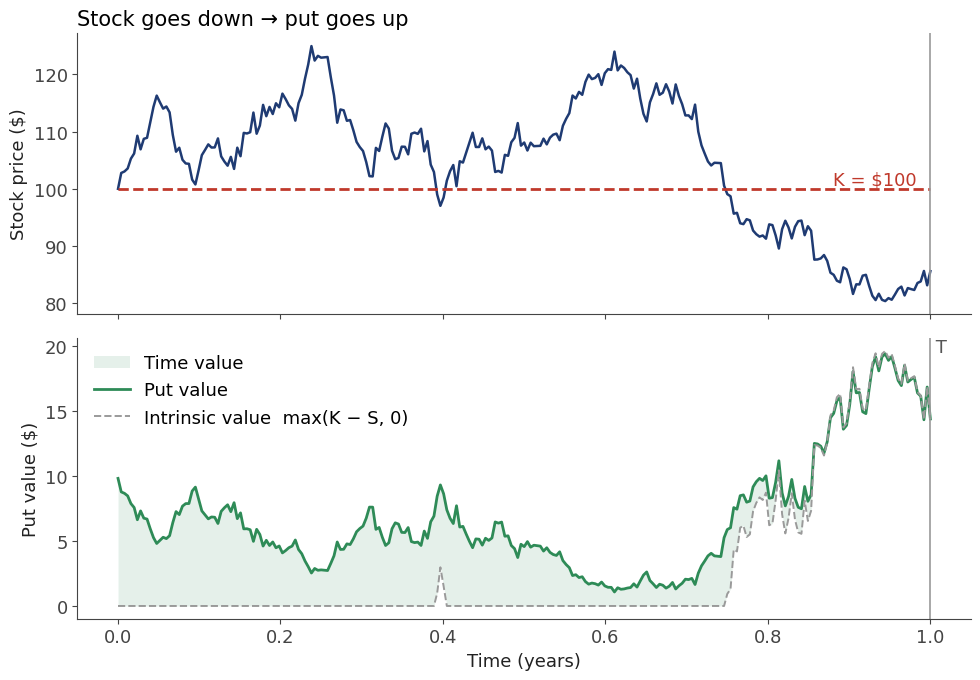

In [4]:
def bs_put(S, K, tau, r, sigma):
    """Black–Scholes European put; tau = time left (years)."""
    S = np.asarray(S, float)
    tau = np.maximum(tau, 1e-12)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return K * np.exp(-r * tau) * norm.cdf(-d2) - S * norm.cdf(-d1)

V = bs_put(S, K, T - t, r, sigma)
V[-1] = max(K - S[-1], 0)          # exactly the payoff at expiry
intrinsic = np.maximum(K - S, 0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1]})

ax1.plot(t, S, color=STOCK, lw=1.8)
ax1.hlines(K, 0, T, color=STRIKE, lw=2, ls="--")
ax1.text(T * 0.99, K, f"K = ${K:.0f} ", color=STRIKE, va="bottom", ha="right")
ax1.set_ylabel("Stock price ($)")
ax1.set_title("Stock goes down → put goes up", loc="left", fontsize=15)

ax2.fill_between(t, intrinsic, V, color=PUT, alpha=0.12, lw=0, label="Time value")
ax2.plot(t, V, color=PUT, lw=2, label="Put value")
ax2.plot(t, intrinsic, color=GREY, lw=1.4, ls="--", label="Intrinsic value  max(K − S, 0)")
ax2.set_ylabel("Put value ($)")
ax2.set_xlabel("Time (years)")
ax2.legend(frameon=False, loc="upper left")

for a in (ax1, ax2):
    a.axvline(T, color=GREY, lw=1.2)
ax2.text(T, ax2.get_ylim()[1], " T", color="#555", va="top")
plt.tight_layout()
if SAVE: plt.savefig("fig2_value_over_time.png", dpi=200)
plt.show()

## 4. Put value vs. stock price, as expiry approaches

Each curve is the put's value for a given amount of time left. As T approaches, the curves bend down onto the **"hockey stick"** payoff max(K − S, 0).

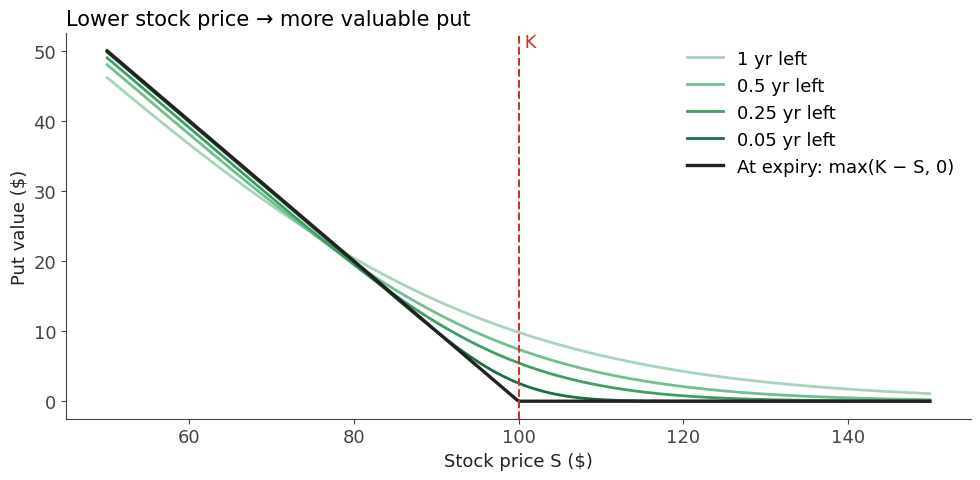

In [5]:
S_grid = np.linspace(50, 150, 400)
times_left = [1.0, 0.5, 0.25, 0.05]
shades = ["#a8d5ba", "#6fbf8f", "#3f9d66", "#1f6e43"]

fig, ax = plt.subplots(figsize=(10, 5))
for tau, c in zip(times_left, shades):
    ax.plot(S_grid, bs_put(S_grid, K, tau, r, sigma), color=c, lw=2,
            label=f"{tau:g} yr left")
ax.plot(S_grid, np.maximum(K - S_grid, 0), color="#222", lw=2.4,
        label="At expiry: max(K − S, 0)")
ax.axvline(K, color=STRIKE, lw=1.5, ls="--")
ax.text(K, ax.get_ylim()[1], " K", color=STRIKE, va="top")

ax.set_xlabel("Stock price S ($)")
ax.set_ylabel("Put value ($)")
ax.set_title("Lower stock price → more valuable put", loc="left", fontsize=15)
ax.legend(frameon=False)
plt.tight_layout()
if SAVE: plt.savefig("fig3_value_vs_price.png", dpi=200)
plt.show()